# Chemistry VAE Example
We will train a VAE on the delaney dataset and a regression model to predict solubility from the latent representation, we will then generate a compound optimized for solubility. Note that the delaney dataset is much smaller than is usally used for a VAE so it would be better to train on a larger dataset of molecules and then train the regression model just for the delaney molecules. We are more likley to see unrealistic molecules with a smaller training set.

# Install Packages
Only run if you do not have packages installed

In [ ]:
%pip install rdkit
%pip install pandas
%pip install scikit-learn
%pip install matplotlib
%pip install torch

# Load data and set seed

In [1]:
import argparse
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from rdkit import Chem, RDLogger
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

df = pd.read_csv("delaney.csv")
#get just SMILES and target columns
TARGET = "measured log(solubility:mol/L)"

df = df[["SMILES", TARGET]].dropna().copy()
    

Device: cpu


# VAE for generating SMILES

In [2]:
class SmilesVAE(nn.Module):
    def __init__(self, vocab_size, pad_id, bos_id, eos_id, latent_dim=16, hidden=128, emb=64):
        super().__init__()
        self.pad_id, self.bos_id, self.eos_id = pad_id, bos_id, eos_id
        self.latent_dim = latent_dim
        #embedd the input SMILES
        self.embedding = nn.Embedding(vocab_size, emb, padding_idx=pad_id)
        #we will use an LSTM as the encoder and decoder
        self.encoder = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        #mean vector for latent representation
        self.to_mu = nn.Linear(2 * hidden, latent_dim)
        #log of variance vector for latent representation
        self.to_logvar = nn.Linear(2 * hidden, latent_dim)
        self.decoder = nn.LSTM(emb + latent_dim, hidden, batch_first=True)
        self.init_decoder = nn.Linear(latent_dim, hidden)
        self.init_cell = nn.Linear(latent_dim, hidden)
        self.output = nn.Linear(hidden, vocab_size)

    def encode(self, inputs, lengths):
        # The encoder only sees actual tokens, not PAD positions.
        emb = self.embedding(inputs)
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (h, c) = self.encoder(packed)
        h = torch.cat((h[-2], h[-1]), dim=-1)
        #return mean and variance
        return self.to_mu(h), self.to_logvar(h)
    
    def decode_teacher_forced(self, decoder_inputs, z):
        #z is the latent representation
        #decoder_inputs is the actual SMILES string, the correct previous token is used in addtion to latent reprepentation
        #to predict output, this is teacher forcing
        emb = self.embedding(decoder_inputs)
        repeated_z = z.unsqueeze(1).expand(-1, emb.size(1), -1)
        inp = torch.cat([emb, repeated_z], dim=-1)
        h0 = torch.tanh(self.init_decoder(z)).unsqueeze(0)
        c0 = torch.tanh(self.init_cell(z)).unsqueeze(0)

        hidden, (h, c) = self.decoder(inp, (h0, c0))
        return self.output(hidden)

    def forward(self, encoder_inputs, lengths, decoder_inputs):
        mu, logvar = self.encode(encoder_inputs, lengths)
        std = torch.exp(0.5 * logvar)
        #calculate z from mean and variation
        z = mu + std * torch.randn_like(std)
        logits = self.decode_teacher_forced(decoder_inputs, z)
        return logits, mu, logvar

    @torch.no_grad()
    def sample_smiles(self, z, id_to_char, max_chars=120, temperature=0.85):
        # One autoregressive decode per batch; temperature only changes sampling.
        self.eval()
        h = torch.tanh(self.init_decoder(z)).unsqueeze(0)
        c = torch.tanh(self.init_cell(z)).unsqueeze(0)
        token = torch.full((z.size(0),), self.bos_id, dtype=torch.long, device=z.device)
        sequences = [''] * z.size(0)
        finished = torch.zeros(z.size(0), dtype=torch.bool, device=z.device)
        for _ in range(max_chars):
            #input previous token and latent representation
            decoder_input = torch.cat([self.embedding(token), z], dim=-1).unsqueeze(1)
            #output and new hidden and cell state
            out, (h, c) = self.decoder(decoder_input, (h, c))
            #choose token based on temperature and random number
            logits = self.output(out[:, 0, :]) / temperature
            logits[:, self.pad_id] = -1e9
            logits[:, self.bos_id] = -1e9
            logits[:, id_to_char.index('<UNK>')] = -1e9
            probs = torch.softmax(logits, dim=-1)
            token = torch.multinomial(probs, 1).squeeze(1)
            for i, t in enumerate(token.tolist()):
                if not bool(finished[i]):
                    #will end generation if end token is produced
                    if t == self.eos_id:
                        finished[i] = True
                    else:
                        sequences[i] += id_to_char[t]
            if bool(finished.all()):
                break
        return sequences


# Regression model

In [3]:
class SolubilityRegressor(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)
        )

    def forward(self, z):
        return self.net(z).squeeze(-1)


# Make tokenized sequences
We will use character level tokens for simplicity

In [4]:
def make_sequences(smiles, char_to_id, pad_id, bos_id, eos_id, max_chars):
    n = len(smiles)
    max_len = max_chars + 1  # characters plus EOS / BOS
    enc = np.full((n, max_len), pad_id, dtype=np.int64)
    dec_in = np.full((n, max_len), pad_id, dtype=np.int64)
    target = np.full((n, max_len), pad_id, dtype=np.int64)
    lengths = []
    for i, s in enumerate(smiles):
        if len(s) > max_chars:
            raise ValueError(f'SMILES has {len(s)} chars > max_chars={max_chars}')
        ids = [char_to_id.get(c, char_to_id['<UNK>']) for c in s]
        tokens = ids + [eos_id]
        inputs = [bos_id] + ids
        enc[i, :len(inputs)] = inputs
        dec_in[i, :len(inputs)] = inputs
        target[i, :len(tokens)] = tokens
        lengths.append(len(inputs))
    return (torch.tensor(enc), torch.tensor(lengths),
            torch.tensor(dec_in), torch.tensor(target))

#make all smiles canonical
def canonical(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol, canonical=True) if mol is not None else None

#maximum lenght of SMILES string
max_chars = 200

df['canonical'] = df['SMILES'].map(canonical)
df = df.dropna(subset=['canonical']).drop_duplicates('canonical').reset_index(drop=True)
df = df[df['SMILES'].str.len() <= max_chars].reset_index(drop=True)
print('Usable molecules:', len(df))

# Split BEFORE fitting the VAE or regressor to avoid fitting on held-out data.
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                          random_state=SEED)
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Vocabulary constructed from training SMILES only
chars = sorted(set("".join(train_df["SMILES"])))

tokens = ["<PAD>", "<BOS>", "<EOS>", "<UNK>"] + chars
char_to_id = {c: i for i, c in enumerate(tokens)}

pad_id, bos_id, eos_id = (
    char_to_id[x] for x in ["<PAD>", "<BOS>", "<EOS>"]
)

# Tokenize all molecules with the training vocabulary
all_seq = make_sequences(
    df["SMILES"].tolist(),
    char_to_id,
    pad_id,
    bos_id,
    eos_id,
    max_chars
)

Usable molecules: 1117


# Make and train VAE model

In [5]:
#set some hyperparameters
vae_epochs = 20 #how many epochs to train the vae
latent_dim = 16 #size of latent representation
beta = 0.01 #weight for KL divergence in loss function
batch_size = 32

#make and train VAE model
vae = SmilesVAE(len(tokens), pad_id, bos_id, eos_id,
                    latent_dim=latent_dim).to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
train_set = TensorDataset(*[a[train_idx] for a in all_seq])
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
print('\nTraining SMILES VAE')
for epoch in range(1, vae_epochs + 1):
    vae.train()
    total_loss = total_recon = total_kl = 0.0
    for enc, lengths, dec_in, target in train_loader:
        enc, lengths = enc.to(device), lengths.to(device)
        dec_in, target = dec_in.to(device), target.to(device)
        logits, mu, logvar = vae(enc, lengths, dec_in)
        # Sum cross entropy across actual tokens, average over molecules.
        recon = nn.functional.cross_entropy(
            logits.reshape(-1, len(tokens)), target.reshape(-1),
            ignore_index=pad_id, reduction='sum') / enc.size(0)
        kl = (-0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(dim=1)).mean()
        # Mild annealing allows initial acquisition of useful sequence codes.
        current_beta = beta * min(1.0, epoch / max(1, vae_epochs * 0.4))
        loss = recon + current_beta * kl
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 5.0)
        opt.step()
        total_loss += loss.item() * len(enc)
        total_recon += recon.item() * len(enc)
        total_kl += kl.item() * len(enc)
    if epoch == 1 or epoch % 5 == 0 or epoch == vae_epochs:
        n = len(train_set)
        print(f'Epoch {epoch:3d}  loss={total_loss/n:.3f}  '
                f'recon={total_recon/n:.3f}  KL={total_kl/n:.3f} beta={current_beta:.3f}')


Training SMILES VAE
Epoch   1  loss=65.475  recon=65.422  KL=42.098 beta=0.010
Epoch   5  loss=32.439  recon=32.184  KL=40.822 beta=0.010
Epoch  10  loss=25.498  recon=25.115  KL=38.245 beta=0.010
Epoch  15  loss=20.961  recon=20.534  KL=42.751 beta=0.010
Epoch  20  loss=17.840  recon=17.378  KL=46.187 beta=0.010


# Make and train regression model

In [6]:
#set hyperparameter
reg_epochs = 20

# Encode every molecule deterministically with the posterior MEAN (not a draw).
vae.eval()
with torch.no_grad():
    mus = []
    for start in range(0, len(df), batch_size):
        enc, lengths = all_seq[0][start:start+batch_size].to(device), \
                        all_seq[1][start:start+batch_size].to(device)
        mu, _ = vae.encode(enc, lengths)
        mus.append(mu.cpu())
    Z = torch.cat(mus)
    
# Train regression model independently from VAE, on training vectors only.
y = df[TARGET].to_numpy(dtype=np.float32)
mean_y, std_y = float(y[train_idx].mean()), float(y[train_idx].std())
yn = (y - mean_y) / std_y
reg = SolubilityRegressor(latent_dim).to(device)
reg_opt = torch.optim.Adam(reg.parameters(), lr=1e-3, weight_decay=1e-4)
reg_loader = DataLoader(TensorDataset(Z[train_idx], torch.tensor(yn[train_idx])),
                        batch_size=batch_size, shuffle=True)

print('\nTraining independent latent-space solubility regressor')
for epoch in range(1, reg_epochs + 1):
    reg.train()
    total = 0
    for z, target in reg_loader:
        z, target = z.to(device), target.to(device)
        loss = nn.functional.mse_loss(reg(z), target)
        reg_opt.zero_grad()
        loss.backward()
        reg_opt.step()
        total += loss.item() * len(z)
    if epoch == 1 or epoch % 5 == 0 or epoch == reg_epochs:
        print(f'Epoch {epoch:3d}  scaled MSE={total/len(train_idx):.3f}')

#evaluate regression model
reg.eval()
with torch.no_grad():
    y_pred = (reg(Z[test_idx].to(device)).cpu().numpy() * std_y + mean_y)
print(f'\nHeld-out solubility regressor: RMSE={np.sqrt(mean_squared_error(y[test_idx],y_pred)):.3f} '
        f'log mol/L; R2={r2_score(y[test_idx],y_pred):.3f}')
print('These measurements estimate prediction quality on encoded test molecules,')
print('not on newly optimized / out-of-distribution molecules.')


Training independent latent-space solubility regressor
Epoch   1  scaled MSE=0.787
Epoch   5  scaled MSE=0.279
Epoch  10  scaled MSE=0.219
Epoch  15  scaled MSE=0.186
Epoch  20  scaled MSE=0.170

Held-out solubility regressor: RMSE=1.048 log mol/L; R2=0.709
These measurements estimate prediction quality on encoded test molecules,
not on newly optimized / out-of-distribution molecules.


# Generate molecules optimized for solubility
We can also use optimizers for searching the latent space - here we are optimizing the representation in latent space based on the gradients showing how a change in latent space will change solubility.

In [8]:
#generation hyperparameters
n_seeds = 20 # number of starting molecules for generation
latent_lr = 0.01 # learning rate for updating latent space representation
optimize_steps = 20 #how many steps of optimization will be done for each latent representation
stay_close = 0.15 #penalty weight for moving too far from starting point
prior_weight = 0.01 #penalty weight for moving too far from prior distribution (generation will be poor there)
samples_per_seed = 5  #how many structures to generate per starting structure
temperature = 0.8 #temperature for decoding generated sequence from latent space

# Start from relatively soluble *training* molecules, not test molecules.
threshold = np.quantile(y[train_idx], 0.65)
seed_ids = [int(i) for i in train_idx if y[i] >= threshold]
random.shuffle(seed_ids)
seed_ids = seed_ids[:n_seeds]
z0 = Z[seed_ids].to(device)
z_opt = z0.clone().detach().requires_grad_(True)
z_optimizer = torch.optim.Adam([z_opt], lr=latent_lr)
# Freeze predictor weights but allow gradient propagation into z_opt.
for param in reg.parameters():
    param.requires_grad_(False)
    
    
print('\nOptimizing latent vectors with gradient ascent')
for step in range(1, optimize_steps + 1):
    # Model predicts STANDARDIZED log-solubility; maximize it.
    predicted = reg(z_opt)
    distance_penalty = (z_opt - z0).square().sum(dim=1).mean()
    prior_penalty = z_opt.square().sum(dim=1).mean()
    objective = predicted.mean() - stay_close * distance_penalty \
                - prior_weight * prior_penalty
    z_optimizer.zero_grad()
    (-objective).backward()
    z_optimizer.step()
    if step == 1 or step % 10 == 0 or step == optimize_steps:
        print(f'Step {step:3d}  predicted standardized logS={predicted.mean().item():.3f} '
              f'distance^2={distance_penalty.item():.3f}')
        
# Sample several SMILES per optimized latent point; generation is stochastic.
z_candidates = z_opt.detach().repeat_interleave(samples_per_seed, dim=0)
generated = []
for chunk in z_candidates.split(64):
    generated.extend(vae.sample_smiles(chunk, tokens, max_chars=max_chars,
                                      temperature=temperature))
train_structures = set(train_df.canonical)
known_structures = set(df.canonical)
records = []
for j, s in enumerate(generated):
    mol_smi = canonical(s)
    seed_no = j // samples_per_seed
    if mol_smi is None:
        continue
    records.append(dict(smiles=mol_smi,
                        predicted_logS=float((reg(z_opt[seed_no:seed_no+1]).item() * std_y) + mean_y),
                        seed_smiles=df.iloc[seed_ids[seed_no]]["SMILES"],
                        seed_measured_logS=float(y[seed_ids[seed_no]]),
                        in_training=mol_smi in train_structures,
                        in_entire_dataset=mol_smi in known_structures))
    
results = pd.DataFrame(records)
valid = len(results)
print(f'Generated {len(generated)} sequences; {valid} valid SMILES ({valid/max(1,len(generated)):.1%}).')
if len(results):
    results = results.drop_duplicates('smiles').copy()
    # Re-encode each decoded SMILES and evaluate its OWN latent representation.
    # This is more meaningful than assigning the optimized z's score unchanged
    # to every stochastic decode, although it remains a model prediction.
    valid_chars = set(chars)
    scorable = results['smiles'].map(lambda s: len(s) <= max_chars and
                                        all(c in valid_chars for c in s)).to_numpy()
    results['reencoded_predicted_logS'] = np.nan
    if scorable.any():
        subset = results.loc[scorable, 'smiles'].tolist()
        seq = make_sequences(subset, char_to_id, pad_id,
                             bos_id, eos_id, max_chars)
        with torch.no_grad():
            predicted_decoded = []
            for start in range(0, len(subset), batch_size):
                enc = seq[0][start:start+batch_size].to(device)
                lengths = seq[1][start:start+batch_size].to(device)
                mu, _ = vae.encode(enc, lengths)
                predicted_decoded.extend((reg(mu) * std_y + mean_y).cpu().numpy().tolist())
        results.loc[scorable, 'reencoded_predicted_logS'] = predicted_decoded
    results = results.sort_values('reencoded_predicted_logS', ascending=False)
    generated_candidates = results.copy()
    print('Unique valid structures:', len(results))
    print('Novel vs training set:', int((~results.in_training).sum()))
    print('\nCandidates (ranked by prediction on re-encoded decoded SMILES):')
    print(results.head(15).to_string(index=False))
else:
    print('No valid structures this run; try more epochs or a better SMILES representation.')
print('\nNote: re-encoded predictions are still from an imperfect learned model.')
print('Validate with independent predictors and ultimately experimental solubility.')


Optimizing latent vectors with gradient ascent
Step   1  predicted standardized logS=0.951 distance^2=0.000
Step  10  predicted standardized logS=1.118 distance^2=0.108
Step  20  predicted standardized logS=1.284 distance^2=0.399
Generated 100 sequences; 45 valid SMILES (45.0%).
Unique valid structures: 38
Novel vs training set: 20

Candidates (ranked by prediction on re-encoded decoded SMILES):
      smiles  predicted_logS     seed_smiles  seed_measured_logS  in_training  in_entire_dataset  reencoded_predicted_logS
   COC(=O)OC        1.103942        COC(=O)C                0.46        False              False                  0.607422
    CC(C)=CO        1.103942        COC(=O)C                0.46        False              False                  0.302026
     CCC(C)O        0.367020      CCC(C)(C)O                0.15         True               True                  0.193760
        CCOC        0.692156           CCC=O                0.58        False              False            

[10:08:36] SMILES Parse Error: unclosed ring for input: 'COc1ccccc1C3'
[10:08:36] non-ring atom 2 marked aromatic
[10:08:36] SMILES Parse Error: unclosed ring for input: 'COc1cccc1O2=O'
[10:08:36] SMILES Parse Error: unclosed ring for input: 'C(=O)NC(=O)C(Cl)N=C(=O)N1Cc2c(NC(C)C(=O))c1c(C)(Cl)C(=O)(O)C'
[10:08:36] SMILES Parse Error: unclosed ring for input: 'OC(=S)(OC1=O)C(=O)C(=O)C(=O)=C2C(C)C2(C)CC=C(=O)C2'
[10:08:36] SMILES Parse Error: extra close parentheses while parsing: C(=O)OC(=O)N(C)C(=O)N(=O)C1c2)c(Cl)c(Cl)c2Cl
[10:08:36] SMILES Parse Error: check for mistakes around position 30:
[10:08:36] O)N(C)C(=O)N(=O)C1c2)c(Cl)c(Cl)c2Cl
[10:08:36] ~~~~~~~~~~~~~~~~~~~~^
[10:08:36] SMILES Parse Error: Failed parsing SMILES 'C(=O)OC(=O)N(C)C(=O)N(=O)C1c2)c(Cl)c(Cl)c2Cl' for input: 'C(=O)OC(=O)N(C)C(=O)N(=O)C1c2)c(Cl)c(Cl)c2Cl'
[10:08:36] SMILES Parse Error: unclosed ring for input: 'OC(=O)C(=S)(F)C1(C)C(O)C2C(=O)OC(=O)C(=O)C2'
[10:08:36] SMILES Parse Error: unclosed ring for input: 'ClP(

# Visualize top 5 generated molecules

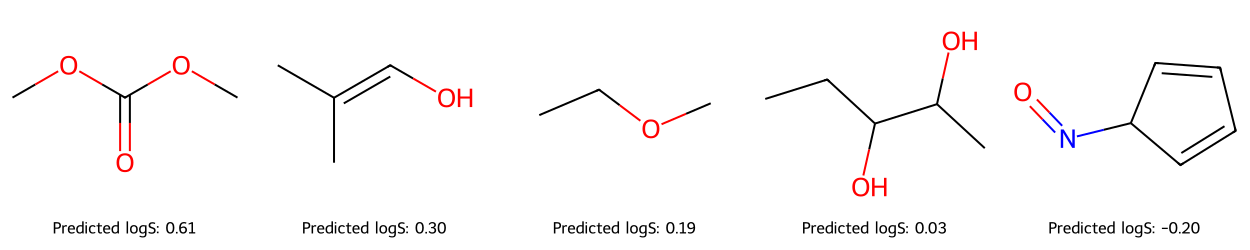

In [9]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

# Select 5 molecules with the highest predicted solubility that are not in the training set
top5 = (
    generated_candidates[
        ~generated_candidates["in_training"]
    ]
    .dropna(subset=["reencoded_predicted_logS"])
    .nlargest(5, "reencoded_predicted_logS")
)

# Convert SMILES to RDKit molecules
mols = [Chem.MolFromSmiles(s) for s in top5["smiles"]]

# Create labels with predicted solubility
legends = [
    f"Predicted logS: {v:.2f}"
    for v in top5["reencoded_predicted_logS"]
]

# Display molecules directly in Jupyter
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=5,
    subImgSize=(250, 250),
    legends=legends
)

display(img)